<a href="https://colab.research.google.com/github/Paul412399/PROIECT-PI/blob/main/Antrenament_Pose_Estimation_Vaci.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q -U ultralytics scikit-learn joblib

In [ ]:
### Celula 2 — Încarcă arhiva

from google.colab import files

uploaded = files.upload()

In [ ]:
import random
import re
import shutil
import zipfile
from collections import defaultdict
from pathlib import Path
import tempfile
import yaml

ZIP_PATH = Path("/content/vaci.zip")
EXTRACT_DIR = Path("/content/cow_data")

if not ZIP_PATH.exists():
    raise FileNotFoundError(f"Nu găsesc arhiva: {ZIP_PATH}")

with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall(EXTRACT_DIR)

source_root = next(
    (
        p.parent for p in EXTRACT_DIR.rglob("data.yaml")
        if (p.parent / "train" / "images").is_dir()
        and (p.parent / "valid" / "images").is_dir()
        and (p.parent / "test" / "images").is_dir()
    ),
    None
)

if source_root is None:
    raise FileNotFoundError("Nu am găsit setul de imagini pose.")

groups = defaultdict(list)

for split in ("train", "valid", "test"):
    image_dir = source_root / split / "images"
    label_dir = source_root / split / "labels"

    for image_path in image_dir.iterdir():
        if not image_path.is_file():
            continue

        label_path = label_dir / f"{image_path.stem}.txt"
        if not label_path.exists():
            raise FileNotFoundError(f"Lipsește adnotarea: {label_path}")

        match = re.match(r"^(.*)-\d+_jpg\.rf\.", image_path.stem)
        video_id = match.group(1) if match else image_path.stem
        groups[video_id].append((image_path, label_path))

video_ids = sorted(groups)
random.Random(42).shuffle(video_ids)

n_train = int(0.70 * len(video_ids))
n_val = int(0.15 * len(video_ids))

split_ids = {
    "train": video_ids[:n_train],
    "valid": video_ids[n_train:n_train + n_val],
    "test": video_ids[n_train + n_val:],
}

dataset_root = Path(tempfile.mkdtemp(prefix="cow_pose_grouped_"))

for split, ids in split_ids.items():
    image_out = dataset_root / split / "images"
    label_out = dataset_root / split / "labels"
    image_out.mkdir(parents=True)
    label_out.mkdir(parents=True)

    for video_id in ids:
        for image_path, label_path in groups[video_id]:
            shutil.copy2(image_path, image_out / image_path.name)
            shutil.copy2(label_path, label_out / label_path.name)

data = yaml.safe_load((source_root / "data.yaml").read_text())
data["train"] = str(dataset_root / "train" / "images")
data["val"] = str(dataset_root / "valid" / "images")
data["test"] = str(dataset_root / "test" / "images")

COLAB_YAML = Path("/content/cow_pose_grouped.yaml")
COLAB_YAML.write_text(yaml.safe_dump(data, sort_keys=False))

print("Clipuri distincte:", len(video_ids))
print("Clipuri train:", len(split_ids["train"]))
print("Clipuri validation:", len(split_ids["valid"]))
print("Clipuri test:", len(split_ids["test"]))
print(COLAB_YAML.read_text())

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
### Celula 4 — Verifică vizual adnotările

import random
import cv2
import matplotlib.pyplot as plt

train_images = list((dataset_root / "train" / "images").glob("*"))
random.seed(42)

for image_path in random.sample(train_images, min(3, len(train_images))):
    label_path = dataset_root / "train" / "labels" / f"{image_path.stem}.txt"
    image = cv2.cvtColor(cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB)

    if label_path.exists():
        height, width = image.shape[:2]

        for line in label_path.read_text().splitlines():
            values = list(map(float, line.split()))
            keypoints = values[5:]

            for i in range(0, len(keypoints), 3):
                x, y, visibility = keypoints[i:i+3]

                if visibility > 0:
                    px, py = round(x * width), round(y * height)
                    cv2.circle(image, (px, py), 4, (255, 0, 0), -1)
                    cv2.putText(
                        image, str(i // 3), (px + 4, py - 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 0), 1
                    )

    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.show()


In [ ]:
### Celula 5 — Montează Google Drive

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
### Celula 6 — Verifică GPU-ul și pornește antrenarea

from pathlib import Path
import torch
from ultralytics import YOLO

DRIVE_DIR = Path("/content/drive/MyDrive")
assert DRIVE_DIR.exists(), "Drive-ul nu pare montat."

PROJECT_DIR = DRIVE_DIR / "cow_pose_runs"
RUN_NAME = "yolov8m_960_grouped"
RUN_DIR = PROJECT_DIR / RUN_NAME
WEIGHTS_DIR = RUN_DIR / "weights"

print("GPU disponibil:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "PyTorch nu vede GPU-ul. Selectează Runtime > Change runtime type > GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Rezultatele vor fi salvate în:", RUN_DIR)

model = YOLO("yolov8m-pose.pt")

results = model.train(
    data=str(COLAB_YAML),
    epochs=150,
    imgsz=960,
    batch=8,
    device=0,
    patience=30,
    workers=2,
    seed=42,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    save=True,
    save_period=5,
    plots=True,
    degrees=10.0,
    translate=0.08,
    scale=0.35,
    fliplr=0.0,
    mosaic=0.5,
    close_mosaic=10
)

In [ ]:
### Celula 7 — Verifică checkpoint-urile din Drive

from pathlib import Path

WEIGHTS_DIR = Path(
    "/content/drive/MyDrive/cow_pose_runs/yolov8m_960_grouped/weights"
)

if WEIGHTS_DIR.exists():
    files = sorted(WEIGHTS_DIR.glob("*.pt"))

    if files:
        for file in files:
            print(f"{file.name}: {file.stat().st_size / 1024 / 1024:.1f} MB")
    else:
        print("Folderul există, dar nu are încă fișiere .pt.")
else:
    print("Folderul nu există încă. Verifică după ce se termină cel puțin o epocă.")

In [ ]:
  ### Celula 8 — Reia antrenarea după o întrerupere


  from pathlib import Path
from ultralytics import YOLO

last_checkpoint = WEIGHTS_DIR / "last.pt"

if not last_checkpoint.exists():
    raise FileNotFoundError(f"Nu am găsit checkpoint-ul: {last_checkpoint}")

model = YOLO(str(last_checkpoint))
results = model.train(resume=True)

In [ ]:
### Celula 9 — Evaluează modelul pe setul de test


from pathlib import Path
from ultralytics import YOLO

best_weights = Path(
    "/content/drive/MyDrive/cow_pose_runs/yolov8m_960/weights/best.pt"
)

if not best_weights.exists():
    raise FileNotFoundError(f"Nu am găsit modelul: {best_weights}")

best_model = YOLO(str(best_weights))

metrics = best_model.val(
    data=str(COLAB_YAML),
    split="test",
    imgsz=960,
    batch=8,
    device=0
)

print(metrics)

In [ ]:
### Celula 10 — Generează predicții pe imagini de test

test_images = list((dataset_root / "test" / "images").glob("*"))

predictions = best_model.predict(
    source=[str(p) for p in test_images[:8]],
    imgsz=960,
    conf=0.25,
    device=0,
    save=True
)

print("Predicțiile sunt salvate în:", predictions[0].save_dir)


0: 960x960 1 cow, 68.4ms
1: 960x960 1 cow, 68.4ms
2: 960x960 1 cow, 68.4ms
3: 960x960 1 cow, 68.4ms
4: 960x960 1 cow, 68.4ms
5: 960x960 1 cow, 68.4ms
6: 960x960 1 cow, 68.4ms
7: 960x960 1 cow, 68.4ms
Speed: 3.9ms preprocess, 68.4ms inference, 2.1ms postprocess per image at shape (1, 3, 960, 960)
Results saved to /content/runs/pose/predict
Predicțiile sunt salvate în: /content/runs/pose/predict


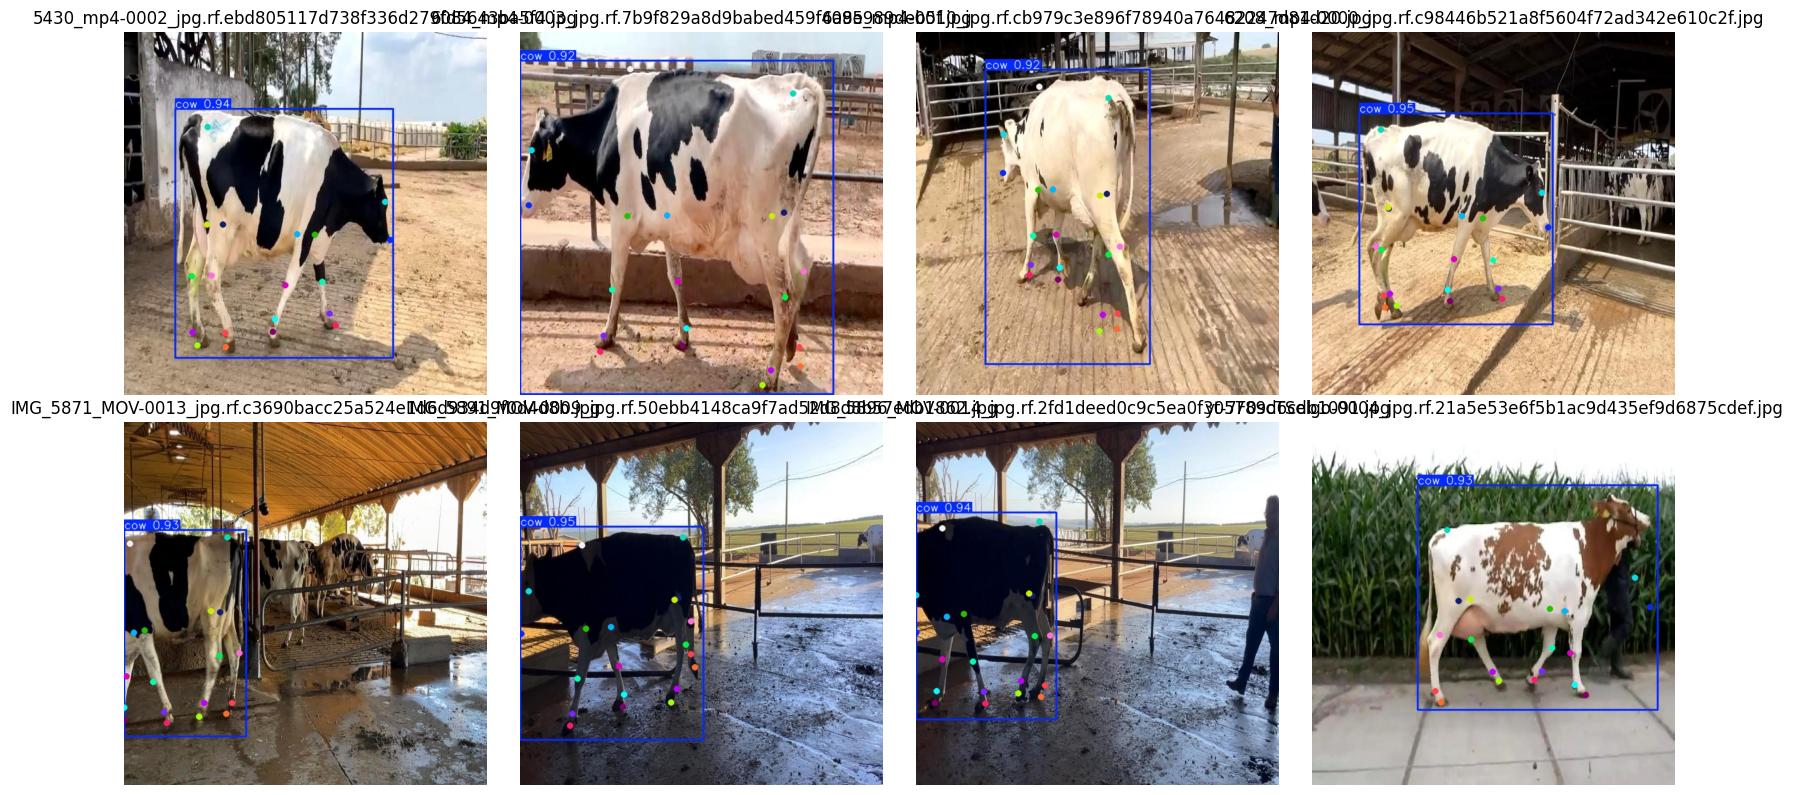

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import math

folder = Path("/content/runs/pose/predict")
imagini = sorted(
    p for p in folder.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

if not imagini:
    print(f"Nu am găsit imagini în {folder}")
else:
    coloane = 4
    randuri = math.ceil(len(imagini) / coloane)
    fig, axe = plt.subplots(randuri, coloane, figsize=(16, 4 * randuri))
    axe = [axe] if randuri * coloane == 1 else axe.flatten()

    for ax, cale in zip(axe, imagini):
        ax.imshow(Image.open(cale))
        ax.set_title(cale.name)
        ax.axis("off")

    for ax in axe[len(imagini):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
